![trader](trader.jpg)


Asset allocation is the most important decision that any investor needs to face. They need to decide how to spread their total capital over certain assets (in this case, stocks). When considering the allocation, the investor wants to balance the risk and the potential reward. At the same time, the allocation depends on factors such as individual goals, risk tolerance, and the investment horizon.

The key framework used in asset allocation is the Modern Portfolio Theory (MPT), which was introduced by the Nobel Prize winner Harry Markowitz. MPT describes how investors can construct portfolios to maximize their expected returns for a given level of risk or, conversely, minimize risk for a given level of expected return. The mathematical framework used to achieve this is called mean-variance optimization.

The main insight from MPT is that investors should not evaluate an asset’s performance alone. Instead, they should evaluate how it would impact the performance of a portfolio of assets. Another important takeaway is the concept of diversification, which means that owning different kinds of assets reduces risk. That is because the loss or gain of a particular security has less impact on the overall portfolio’s performance.

**Your task**

In the dynamic realm of finance, data scientists/analysts are often tasked with finding optimal investment strategies. Imagine you're one such analyst, and you were asked to build an effective portfolio comprising FAANG stocks – Facebook (Meta), Apple, Amazon, Netflix, and Google. Your goal is to maximize returns while mitigating risk.

In this project, you are tasked to find the optimal allocation to the FAANG stocks based on historical stock price data spanning the years 2020-2023. The dataset is stored in the `faang_stocks.csv` file. For each trading day, it contains the close prices of the five tech companies.


In [36]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pypfopt.efficient_frontier import EfficientFrontier
from pypfopt import risk_models
from pypfopt import expected_returns



# Loading data
stock_prices_df = pd.read_csv("faang_stocks.csv", index_col="Date")

# Changing the index to a datetime type allows for easier filtering and plotting.
stock_prices_df.index = pd.to_datetime(stock_prices_df.index)
stock_prices_df

,AAPL,AMZN,GOOGL,META,NFLX
Date,,,,,
2020-01-02,75.09,94.90,68.43,209.78,329.81
2020-01-03,74.36,93.75,68.08,208.67,325.90
2020-01-06,74.95,95.14,69.89,212.60,335.83
2020-01-07,74.60,95.34,69.76,213.06,330.75
2020-01-08,75.80,94.60,70.25,215.22,339.26
...,...,...,...,...,...
2023-12-22,193.60,153.42,141.49,353.39,486.76
2023-12-26,193.05,153.41,141.52,354.83,491.19
2023-12-27,193.15,153.34,140.37,357.83,491.79


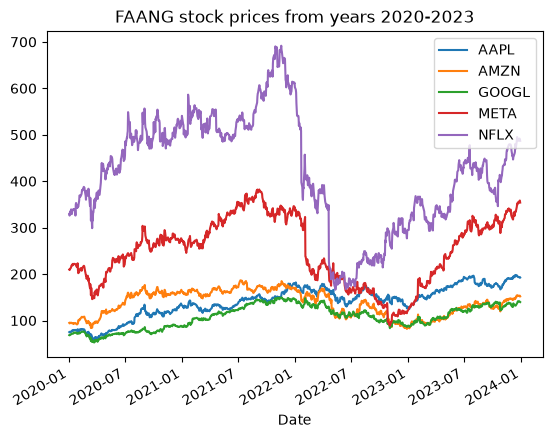

In [37]:
# Plotting the stock prices
stock_prices_df.plot(title="FAANG stock prices from years 2020-2023");

In [38]:
# Use however many cells you need to complete this exercise.
# Please remember to store the requested outputs in the correct objects!

In [39]:
# Info of stock price
stock_prices_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1006 entries, 2020-01-02 to 2023-12-29
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    1006 non-null   float64
 1   AMZN    1006 non-null   float64
 2   GOOGL   1006 non-null   float64
 3   META    1006 non-null   float64
 4   NFLX    1006 non-null   float64
dtypes: float64(5)
memory usage: 47.2 KB


In [40]:
#Describe Stock price
stock_prices_df.describe()

,AAPL,AMZN,GOOGL,META,NFLX
count,1006.000000,1006.000000,1006.000000,1006.000000,1006.000000
mean,140.808101,137.216163,107.870219,249.362266,420.203350
std,33.313922,27.468851,25.114959,71.002682,120.829682
min,56.090000,81.820000,52.710000,88.910000,166.370000
25%,123.592500,114.307500,88.027500,193.565000,337.590000
50%,145.860000,140.585000,109.885000,259.915000,428.305000
75%,166.215000,161.190000,130.250000,310.547500,509.102500
max,198.110000,186.570000,149.840000,382.180000,691.690000


In [41]:
#Return prices df
returns_df= stock_prices_df.pct_change().dropna()
returns_df.head(),returns_df.tail()

(                AAPL      AMZN     GOOGL      META      NFLX
 Date                                                        
 2020-01-03 -0.009722 -0.012118 -0.005115 -0.005291 -0.011855
 2020-01-06  0.007934  0.014827  0.026586  0.018834  0.030469
 2020-01-07 -0.004670  0.002102 -0.001860  0.002164 -0.015127
 2020-01-08  0.016086 -0.007762  0.007024  0.010138  0.025729
 2020-01-09  0.021240  0.004757  0.010534  0.014311 -0.010611,
                 AAPL      AMZN     GOOGL      META      NFLX
 Date                                                        
 2023-12-22 -0.005548 -0.002730  0.007620 -0.001977 -0.009866
 2023-12-26 -0.002841 -0.000065  0.000212  0.004075  0.009101
 2023-12-27  0.000518 -0.000456 -0.008126  0.008455  0.001222
 2023-12-28  0.002226  0.000261 -0.000997  0.001369 -0.002603
 2023-12-29 -0.005424 -0.009388 -0.003851 -0.012168 -0.007400)

In [42]:
# Describe Return
(returns_df.describe() * 100).round(3)

,AAPL,AMZN,GOOGL,META,NFLX
count,100500.000,100500.000,100500.000,100500.000,100500.000
mean,0.116,0.075,0.093,0.096,0.088
std,2.115,2.374,2.112,2.947,3.067
min,-12.865,-14.053,-11.629,-26.390,-35.117
25%,-0.910,-1.214,-0.964,-1.234,-1.405
50%,0.093,0.078,0.108,0.114,0.076
75%,1.274,1.332,1.204,1.504,1.445
max,11.972,13.533,9.230,23.282,16.854


<Axes: title={'center': 'Returns of stock Prices'}, xlabel='Date', ylabel='Stock Returns'>

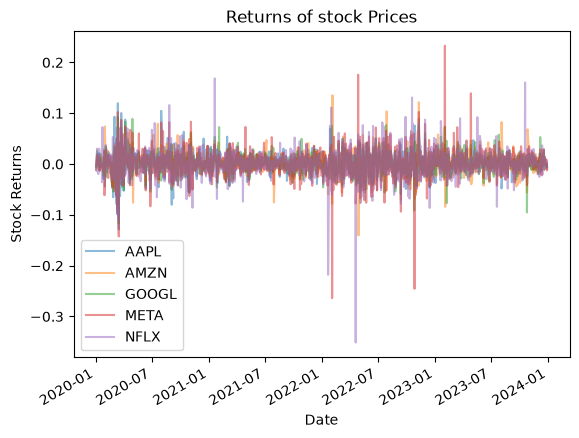

In [43]:
returns_df.plot(title= "Returns of stock Prices",xlabel = "Date",ylabel = "Stock Returns",alpha = 0.5)

<Figure size 2000x1200 with 0 Axes>

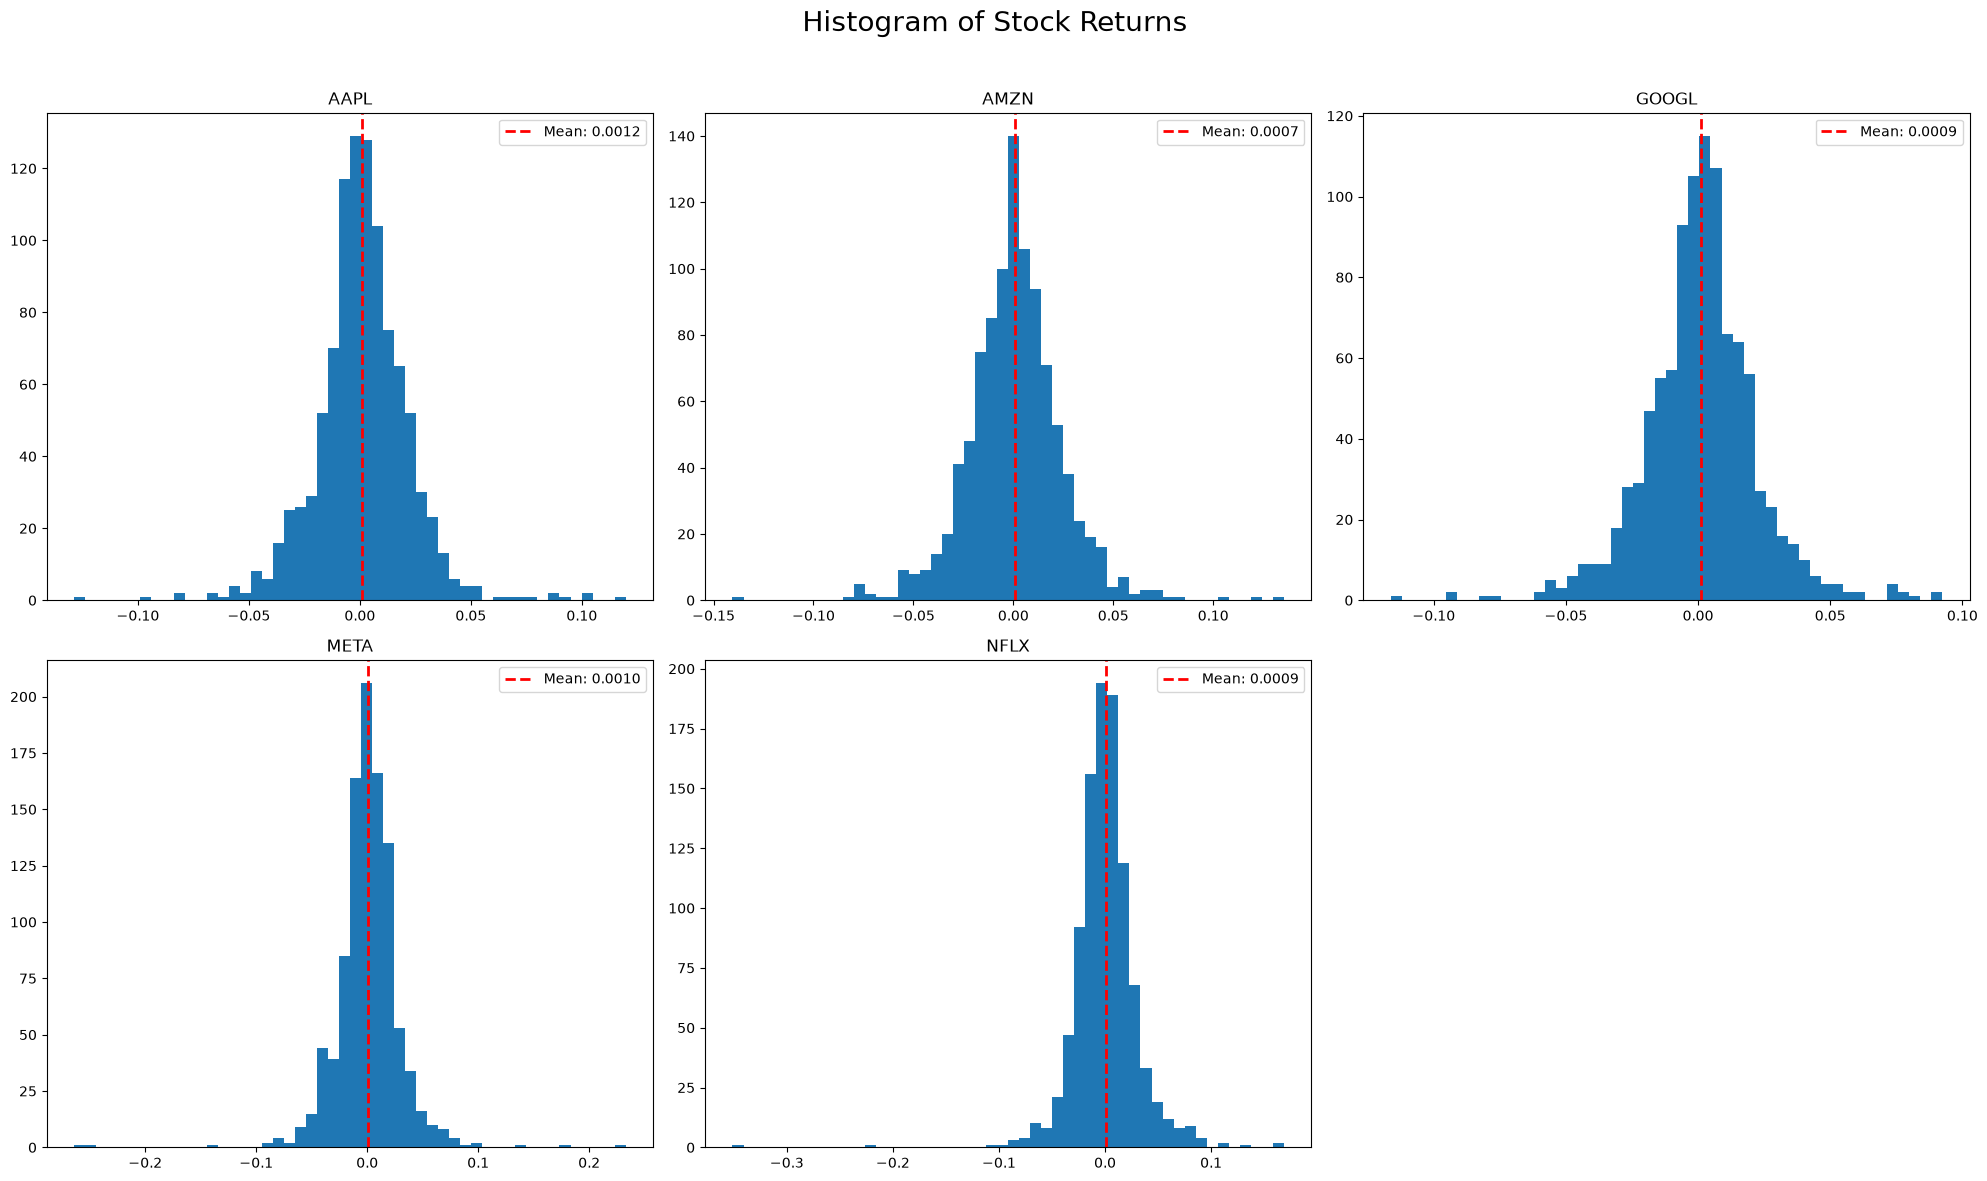

,Kurtosis,Skewness
AAPL,4.879370,0.078994
AMZN,3.762571,0.097829
GOOGL,3.226088,-0.094426
META,16.887989,-0.575407
NFLX,21.768905,-1.329683


In [44]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd  # Ensure pandas is imported

plt.figure(figsize=(20, 12))

# Create histograms and get axes
axes = returns_df.hist(figsize=(20, 12), bins=50, layout=(2, 3), grid=False)
axes = axes.flatten()

# Add vertical line for mean on each subplot
for i, col in enumerate(returns_df.columns):
    mean_val = returns_df[col].mean()
    axes[i].axvline(mean_val, color='red', linestyle='dashed', linewidth=2, label=f"Mean: {mean_val:.4f}")
    axes[i].legend()

plt.suptitle("Histogram of Stock Returns", fontsize=20)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Fix: pass a list of Series to pd.concat, and optionally give keys for clarity
summary_stats = pd.concat(
    [returns_df.kurt(), returns_df.skew()],
    axis=1,
    keys=['Kurtosis', 'Skewness']
)
summary_stats

In [45]:
#Set portfolio Equally Weights

ew=np.repeat((100/len(stock_prices_df.columns))/100,len(stock_prices_df.columns))
ew

array([0.2, 0.2, 0.2, 0.2, 0.2])

In [46]:
#Expected Return 
portfolio_equially_w_expected_return = (returns_df*np.sqrt(252)).dot(ew).mean()
portfolio_equially_w_expected_return
benchmark_exp_return = portfolio_equially_w_expected_return
#Expected std
portfolio_equially_w_expected_cov=risk_models.sample_cov(stock_prices_df)
vol= (returns_df*np.sqrt(252)).dot(ew).std()
#Expected sharpe ratio
portfolio_equially_w_expected_sp = (portfolio_equially_w_expected_return/vol)*np.sqrt(252)
benchmark_sharpe_ratio = portfolio_equially_w_expected_sp
portfolio_metrics = pd.DataFrame({
    'Metric': ['Expected Return', 'Expected Std Dev', 'Sharpe Ratio'],
    'Value': [
        portfolio_equially_w_expected_return, 
        vol, 
        portfolio_equially_w_expected_sp
          ]
})
print(portfolio_metrics)



             Metric     Value
0   Expected Return  0.014870
1  Expected Std Dev  0.326851
2      Sharpe Ratio  0.722187


In [47]:
#Minimum Volatility
# Calculate expected returns mu 
mu = expected_returns.mean_historical_return(stock_prices_df)

# Calculate the covariance matrix S
Sigma = risk_models.sample_cov(stock_prices_df)

# Efficient frontier
ef = EfficientFrontier(mu,Sigma)

mu,Sigma

(AAPL     0.266293
 AMZN     0.125263
 GOOGL    0.195944
 META     0.140163
 NFLX     0.102594
 dtype: float64,
            AAPL      AMZN     GOOGL      META      NFLX
 AAPL   0.112683  0.078926  0.077773  0.095367  0.077774
 AMZN   0.078926  0.142040  0.083945  0.108089  0.101851
 GOOGL  0.077773  0.083945  0.112423  0.106969  0.076233
 META   0.095367  0.108089  0.106969  0.218838  0.116967
 NFLX   0.077774  0.101851  0.076233  0.116967  0.237020)

In [48]:
# Calculate weights for the minimum volatility portfolio
raw_weights_minvol = ef.min_volatility()
cleaned_weights_minvol = ef.clean_weights()

# Show portfolio performance
print(cleaned_weights_minvol)
min_vol_performance = ef.portfolio_performance(risk_free_rate = 0)

OrderedDict({'AAPL': 0.39842, 'AMZN': 0.14911, 'GOOGL': 0.3829, 'META': 0.0, 'NFLX': 0.06957})


In [49]:
mv_portfolio_vol = min_vol_performance[1]
mv_portfolio=pd.Series(ef.clean_weights())

In [50]:

ef_maxsharpe = EfficientFrontier(returns_df.mean()*252, returns_df.cov()*252)
raw_weights_maxsharpe = ef_maxsharpe.max_sharpe(risk_free_rate=0)
cleaned_weights_maxsharpe = ef_maxsharpe.clean_weights()


print(raw_weights_maxsharpe, cleaned_weights_maxsharpe)
ef_max_sharpe_performance = ef_maxsharpe.portfolio_performance(verbose=True)

OrderedDict({'AAPL': 0.7874404759681178, 'AMZN': 0.0, 'GOOGL': 0.1996981317401154, 'META': 0.0, 'NFLX': 0.0128613922917667}) OrderedDict({'AAPL': 0.78744, 'AMZN': 0.0, 'GOOGL': 0.1997, 'META': 0.0, 'NFLX': 0.01286})
Expected annual return: 28.0%
Annual volatility: 31.8%
Sharpe Ratio: 0.88


In [51]:
ms_portfolio_sharpe = ef_max_sharpe_performance[2]
ms_portfolio=pd.Series(cleaned_weights_maxsharpe)
ms_portfolio

AAPL     0.78744
AMZN     0.00000
GOOGL    0.19970
META     0.00000
NFLX     0.01286
dtype: float64

In [61]:
resultados = {
    "Portafolio 1": (portfolio_equially_w_expected_return, vol, benchmark_sharpe_ratio),
    "Portafolio 2": (min_vol_performance[0], min_vol_performance[1], min_vol_performance[2]),
    "Portafolio 3": (ef_max_sharpe_performance[0], ef_max_sharpe_performance[1], ef_max_sharpe_performance[2]),
}

tabla = pd.DataFrame.from_dict(
    resultados,
    orient="index",
    columns=["Retorno esperado", "Volatilidad", "Sharpe ratio"]
)

tabla["Retorno esperado"] = tabla["Retorno esperado"].map("{:.2%}".format)
tabla["Volatilidad"] = tabla["Volatilidad"].map("{:.2%}".format)
tabla["Sharpe ratio"] = tabla["Sharpe ratio"].map("{:.3f}".format)

display(tabla)

,Retorno esperado,Volatilidad,Sharpe ratio
Portafolio 1,1.49%,32.69%,0.722
Portafolio 2,20.69%,30.31%,0.683
Portafolio 3,28.01%,31.75%,0.882
